# **1. Dataset Construction**

**1.1 Sinc Funtion Data with Noise**

In [1]:
# importing necessary llibraries
import torch
import matplotlib.pyplot as plt
import numpy as np

*1.1.1 Data Generation*

In [112]:
# generating 1D input values
x = torch.linspace(-10,10,10000)

In [113]:
# computing sinc values and also the hadling the case of x = 0
actual_y = torch.where(x == 0 , torch.tensor(1.0), torch.sin(x)/x)

In [114]:
# adding gaussian noise
noise = 0.01 * torch.randn_like(x)
noisy_y = actual_y + noise

*1.1.2 Visualization*

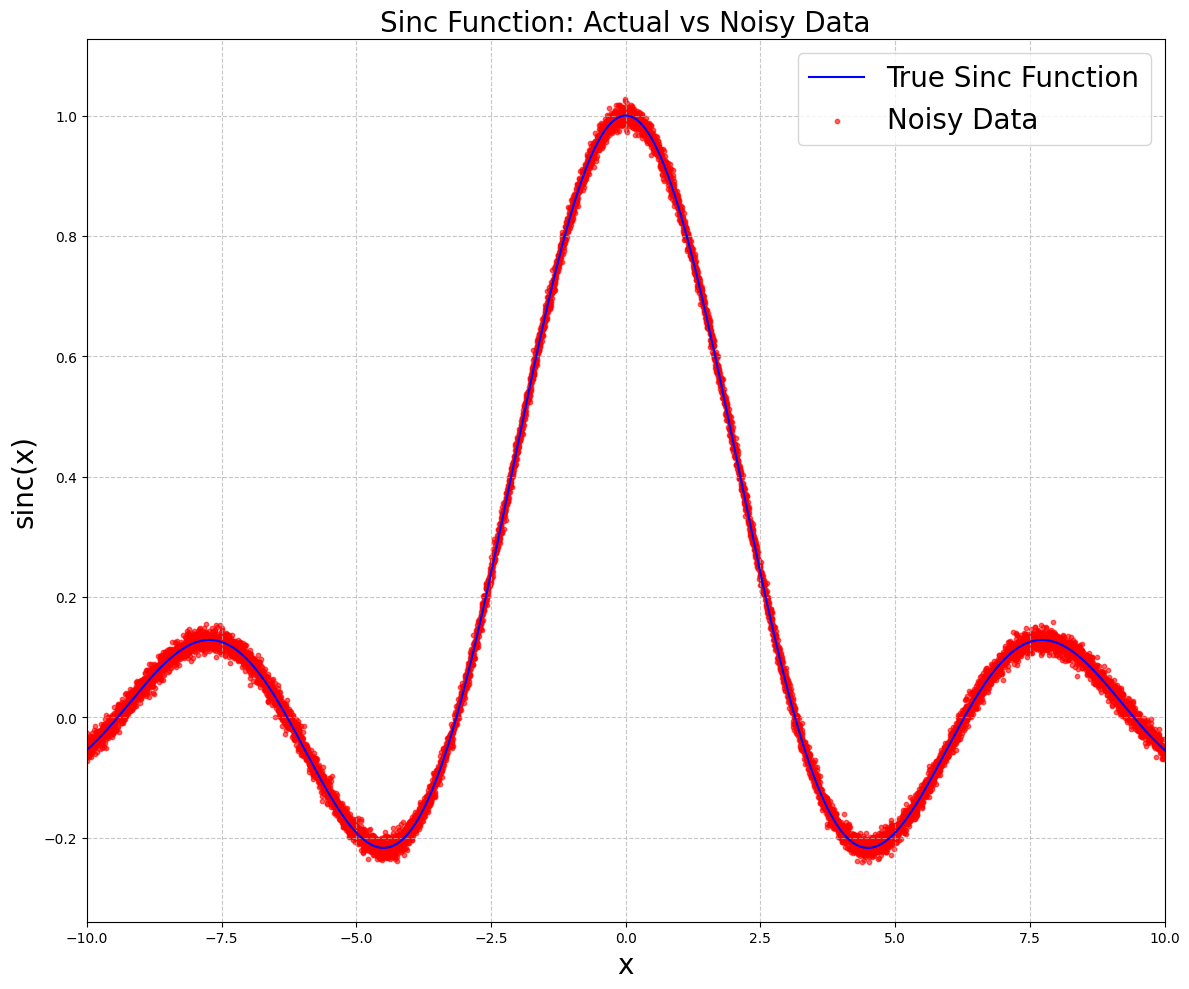

In [115]:
# making visualization for sinc function and noisy data
# making visualization for sinc function and noisy data
plt.figure(figsize = (12,10))
plt.plot(x.numpy(), actual_y.numpy(), label = 'True Sinc Function', color = 'blue')
plt.scatter(x.numpy(), noisy_y.numpy(), label = 'Noisy Data', color = 'red', alpha = 0.6, s = 10)
plt.title('Sinc Function: Actual vs Noisy Data', fontsize = 20)
plt.xlabel('x', fontsize = 20)
plt.ylabel('sinc(x)', fontsize = 20)
plt.legend(fontsize = 20)
plt.xlim(-10,10)
plt.ylim(min(noisy_y)-0.1, max(noisy_y)+0.1)
plt.tight_layout()
plt.grid(True, linestyle = '--', alpha = 0.7)
plt.show()

# **2.Multilayer Perceptron (MLP) with Two Hidden Layers**

**2.1 Model Architecture & Setup**

*2.1.1 Defining the MLP Model*

In [116]:
# creating MLP(torch.nn.module) class
class MLP(torch.nn.Module):
  # This is Mutilayer Perceptron with two hidden layers for approximating the sinc function,
  def __init__(self, input_size = 1, hidden_size1 = 64, hidden_size2 = 32, output_size = 1):
    '''
    Here we are intializing MLP with two hidden layers.
    Args are :
      input_size (int):this is the size of the input features (1 for 1D sinc function)
      hidden_size1(int):this is the size of the first hidden layer, default is 64
      hidden_size2(int):this is the size of the second hidden layer, default is 64
      output_size(int):this is the size of the output
    '''
    super(MLP, self).__init__()

    # input layer to first hidden layer
    self.fc1 = torch.nn.Linear(input_size, hidden_size1)

    # first hidden layer to second hidden layer
    self.fc2 = torch.nn.Linear(hidden_size1, hidden_size2)

    # second hidden layer to output layer
    self.fc3 = torch.nn.Linear(hidden_size2, output_size)

  def forward(self, x):
    # first hidden layer wieth RELU activation
    x = torch.nn.functional.relu(self.fc1(x))

    # first hidden layer wieth RELU activation
    x = torch.nn.functional.relu(self.fc2(x))

    # output layer (no activation)
    x = self.fc3(x)

    return x


*2.1.2 Hyperparameters and setup*

In [117]:
# hyperparameter setup
batch_size = 64
learning_rate = 0.01
num_epochs = 100

# initializing sizes for layes in neural networks
input_size = 1
hidden_size1 = 64
hidden_size2 = 32
output_size = 1

# creating model instance
model = MLP(input_size, hidden_size1, hidden_size2, output_size)

# creating loss function
loss_func = torch.nn.MSELoss()

# creating optimizer
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)

# printing the model architecture for verification
print(model)

MLP(
  (fc1): Linear(in_features=1, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)


**2.2 Training the MLP**

*2.2.1 Data Preparation*

In [118]:
# reshaping the data
inputs = x.unsqueeze(1) #reshaping x to (1000,1)
outputs = noisy_y.unsqueeze(1) #reshaping noisy_y to (1000,1)

# making proper datasets
sinc_dataset = torch.utils.data.TensorDataset(inputs, outputs)
data_loader = torch.utils.data.DataLoader(sinc_dataset,batch_size=batch_size, shuffle=True)

*2.2.2 Training Loop*

In [119]:
# training loop
training_losses = []

for epoch in range(num_epochs):
  epoch_loss = 0.0
  for batch_idx, (input_batch, output_batch) in enumerate(data_loader):
    # forward pass
    predictions = model(input_batch)
    loss = loss_func(predictions,output_batch)
    # backward pass and optimization
    optimizer.zero_grad() #clearing gradients
    loss.backward() # computing gradients
    optimizer.step() #updating parameters

    # loss for each epoch
    epoch_loss +=loss.item()

  # average loss for epoch
  epoch_loss /= len(data_loader)
  training_losses.append(epoch_loss)

  # printing lossess
  print(f"Epoch {epoch + 1}/{num_epochs},Loss: {epoch_loss:.4f} ")

# printing the final training losses
print("Training complete.")
print(f"Final loss: {training_losses[-1]:.4f}")

Epoch 1/100,Loss: 0.0798 
Epoch 2/100,Loss: 0.0405 
Epoch 3/100,Loss: 0.0281 
Epoch 4/100,Loss: 0.0201 
Epoch 5/100,Loss: 0.0154 
Epoch 6/100,Loss: 0.0128 
Epoch 7/100,Loss: 0.0153 
Epoch 8/100,Loss: 0.0162 
Epoch 9/100,Loss: 0.0122 
Epoch 10/100,Loss: 0.0086 
Epoch 11/100,Loss: 0.0098 
Epoch 12/100,Loss: 0.0077 
Epoch 13/100,Loss: 0.0066 
Epoch 14/100,Loss: 0.0077 
Epoch 15/100,Loss: 0.0060 
Epoch 16/100,Loss: 0.0066 
Epoch 17/100,Loss: 0.0069 
Epoch 18/100,Loss: 0.0065 
Epoch 19/100,Loss: 0.0065 
Epoch 20/100,Loss: 0.0063 
Epoch 21/100,Loss: 0.0055 
Epoch 22/100,Loss: 0.0060 
Epoch 23/100,Loss: 0.0055 
Epoch 24/100,Loss: 0.0057 
Epoch 25/100,Loss: 0.0055 
Epoch 26/100,Loss: 0.0056 
Epoch 27/100,Loss: 0.0053 
Epoch 28/100,Loss: 0.0055 
Epoch 29/100,Loss: 0.0051 
Epoch 30/100,Loss: 0.0052 
Epoch 31/100,Loss: 0.0054 
Epoch 32/100,Loss: 0.0051 
Epoch 33/100,Loss: 0.0053 
Epoch 34/100,Loss: 0.0051 
Epoch 35/100,Loss: 0.0051 
Epoch 36/100,Loss: 0.0050 
Epoch 37/100,Loss: 0.0054 
Epoch 38/1

*2.2.3 Visualization of Training Loss*

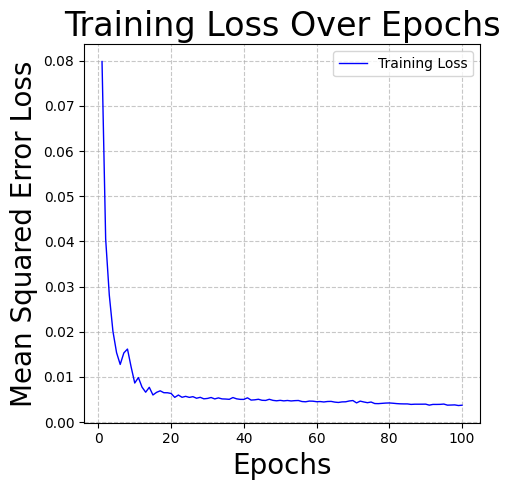

In [120]:
# visualization of training loss
plt.figure(figsize = (5,5))
plt.plot(range(1,len(training_losses)+1), training_losses, label = 'Training Loss', color = 'blue', linewidth = 1)
plt.xlabel('Epochs', fontsize = 20)
plt, plt.ylabel('Mean Squared Error Loss', fontsize = 20)
plt.title('Training Loss Over Epochs', fontsize = 24)
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.7)
plt.tight_layout()
plt.show()

**Decision Boundary Visualization**

*2.3.1 Generate a Mesh Grid*

In [121]:
x_range = np.linspace(-10,10,10000)
x_mesh = x_range.reshape(-1,1)
x_tensor = torch.tensor(x_mesh, dtype = torch.float32)

*2.3.2 Prediction over the grid*

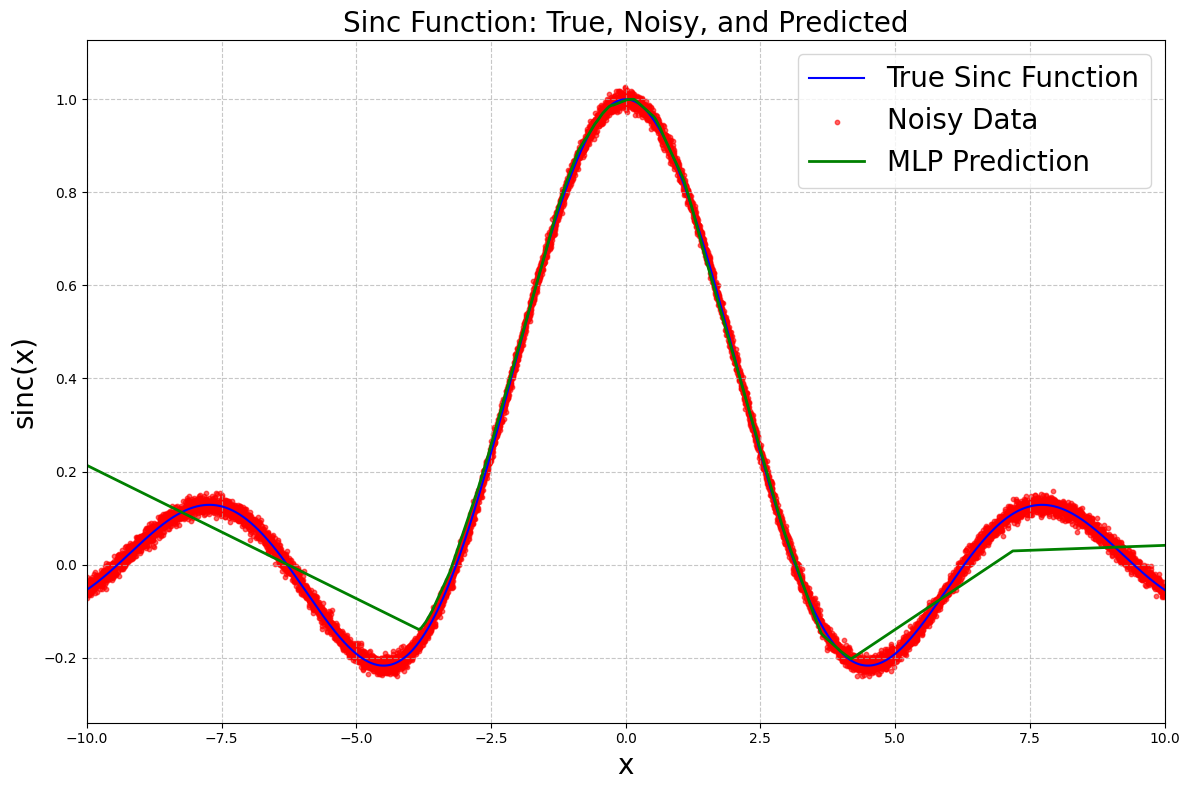

In [122]:
# setting the model to evaluation mode
model.eval()

# using torch.no_grad() to compute predictions over the grid
with torch.no_grad():
  y_pred = model(x_tensor)

# converting and reshaping tensors for visualization
y_pred_np = y_pred.squeeze().numpy()
x_range_reshaped = x_range.reshape(-1,1)

# visualizing the results
plt.figure(figsize=(12, 8))

# plotting the true sinc function
plt.plot(x.numpy(), actual_y.numpy(), label = 'True Sinc Function', color = 'blue')

# plotting the noisy data
plt.scatter(x.numpy(), noisy_y.numpy(), label = 'Noisy Data', color = 'red', alpha = 0.6, s = 10)

# plotting the model predictions
plt.plot(x_range, y_pred_np, label = 'MLP Prediction', color = 'green', linewidth = 2)

# adding labels and legend
plt.title('Sinc Function: True, Noisy, and Predicted', fontsize = 20)
plt.xlabel('x', fontsize = 20)
plt.ylabel('sinc(x)', fontsize = 20)
plt.legend(fontsize = 20)
plt.xlim(-10,10)
plt.ylim(min(noisy_y)-0.1, max(noisy_y)+0.1)
plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# **3. Introduction to CNN with PyTorch**

**3.1 Data Preparation**

In [74]:
# importing necessary libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image
import os
import matplotlib.pyplot as plt
import numpy as np
import zipfile
import time

In [75]:
# extracting the zip file which was downloaded from kaggle
local_zip = '/content/archive.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/content/archive')
zip_ref.close()

In [76]:
# creating custom Dataset class
class RockPaperScissorsDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        if not os.path.isdir(self.data_dir):
             raise ValueError(f"[Dataset Error] Data directory not found or is not a directory: '{self.data_dir}'")

        self.classes = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
        expected_classes = {'rock', 'paper', 'scissors'}
        if not set(self.classes).issuperset(expected_classes):
             print(f"[Dataset Warning] Expected classes 'rock', 'paper', 'scissors', but found {self.classes} in '{self.data_dir}'. Check the path.")
        if len(self.classes) == 0:
             raise ValueError(f"[Dataset Error] No class subdirectories ('rock', 'paper', 'scissors') found directly inside '{self.data_dir}'.")

        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}

        self.samples = self._make_dataset()

        if not self.samples:
            raise ValueError(f"[Dataset Error] No valid image files (.png, .jpg, .jpeg, .bmp, .gif) found in the class subdirectories of '{self.data_dir}'")
        print(f"Dataset initialized: Found {len(self.samples)} images in {len(self.classes)} classes ({self.classes}).")

    def _make_dataset(self):
        images = []
        valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp', '.gif')
        print(f"Looking for images in: {self.data_dir}")
        if not self.classes: return images

        for target_class in self.classes:
            class_index = self.class_to_idx[target_class]
            target_dir = os.path.join(self.data_dir, target_class)
            if not os.path.isdir(target_dir):
                print(f"[Dataset Warning] Expected directory not found: {target_dir}")
                continue
            found_in_class = 0
            for fname in sorted(os.listdir(target_dir)):
                if fname.lower().endswith(valid_extensions):
                    path = os.path.join(target_dir, fname)
                    item = (path, class_index)
                    images.append(item)
                    found_in_class += 1
        return images

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, target = self.samples[idx]
        try:
            img = Image.open(img_path).convert('RGB')
        except Exception as e:
            print(f"[Dataset Warning] Error loading image {img_path}: {e}. Skipping.")
            return None
        if self.transform:
            img = self.transform(img)
        return img, target

In [77]:
# creating data transforms
img_size = (150,150)
batch_size = 64
num_classes = 3
data_transforms = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# specifying Dataset path
dataset_path = '/content/archive/rps-cv-images'

In [78]:
# instantiating the Full dataset
try:
    full_dataset = RockPaperScissorsDataset(data_dir=dataset_path, transform=data_transforms)
    if len(full_dataset) == 0:
         print("[Warning] Dataset loaded but contains zero samples. Check data path and image files.")
         full_dataset = None
    else:
         print(f"Successfully loaded dataset. Total images: {len(full_dataset)}")

except ValueError as e:
    print(e)
    print(f"Please verify that '{dataset_path}' is the correct path directly containing the 'rock', 'paper', 'scissors' subdirectories.")
    full_dataset = None
except Exception as e:
    print(f"An unexpected error occurred during dataset loading: {e}")
    full_dataset = None


Looking for images in: /content/archive/rps-cv-images
Dataset initialized: Found 2188 images in 3 classes (['paper', 'rock', 'scissors']).
Successfully loaded dataset. Total images: 2188


In [79]:
# splliting the data into training and test sets
if full_dataset and len(full_dataset) > 0:
    train_ratio = 0.8
    total_size = len(full_dataset)
    train_size = int(train_ratio * total_size)
    test_size = total_size - train_size
    if train_size + test_size != total_size: train_size = total_size - test_size # Adjust for rounding
    train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])
    print(f"Dataset split complete: Train={len(train_dataset)}, Test={len(test_dataset)}")
else:
    print("Dataset not loaded or empty, skipping train/test split.")
    train_dataset, test_dataset = None, None

Dataset split complete: Train=1750, Test=438


In [80]:
# Creating DataLoaders
def collate_fn_skip_none(batch):
    batch = list(filter(lambda x: x is not None and x[0] is not None, batch))
    if not batch: return torch.Tensor(), torch.Tensor()
    return torch.utils.data.dataloader.default_collate(batch)

if train_dataset and test_dataset:
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn_skip_none, num_workers=2, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn_skip_none, num_workers=2, pin_memory=True)
    print("DataLoaders created.")
else:
    print("Skipping DataLoader creation.")
    train_loader, test_loader = None, None

DataLoaders created.


**3.2 Understanding Convolutions**

In [81]:
if train_loader:
    try:
        # getting one batch of images and labels
        images, labels = next(iter(train_loader))
        # Selecting a single image from the batch
        single_image = images[0]
        # Adding a batch dimension (required for Conv2d)
        single_image_batch = single_image.unsqueeze(0)
        print(f"Loaded single image with shape: {single_image_batch.shape}") # Should be [1, C, H, W]
        # Getting the expected input channels
        input_channels = single_image_batch.shape[1] # Should be 3 for RGB
    except StopIteration:
        print("Train loader is empty. Cannot fetch an image.")
        single_image_batch = None
        input_channels = 3 # Default to 3 channels if loader fails
    except Exception as e:
        print(f"An error occurred while loading image from DataLoader: {e}")
        single_image_batch = None
        input_channels = 3 # Default to 3 channels on error
else:
    print("Train loader not available. Cannot fetch an image.")
    single_image_batch = None
    input_channels = 3 # Default to 3 channels if no loader


Loaded single image with shape: torch.Size([1, 3, 150, 150])


In [82]:
# Building a modular CNN class using PyTorch's nn.Module
class SimpleCNN(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding)

    def forward(self, x):
        # Applying the convolutional layer
        x = self.conv1(x)
        return x

In [83]:
# creating function to calculate output size (Helper for verification
def calculate_conv_output_size(H_in, W_in, kernel_size, padding=0, stride=1):
    if isinstance(kernel_size, int): kernel_size = (kernel_size, kernel_size)
    if isinstance(padding, int): padding = (padding, padding)
    if isinstance(stride, int): stride = (stride, stride)

    H_out = np.floor(((H_in + 2 * padding[0] - kernel_size[0]) / stride[0]) + 1)
    W_out = np.floor(((H_in + 2 * padding[1] - kernel_size[1]) / stride[1]) + 1)
    return int(H_out), int(W_out)

In [84]:
# Instantiating the model and verifying output size
if single_image_batch is not None:
    C_in = input_channels # Number of input channels (e.g., 3 for RGB)
    H_in, W_in = single_image_batch.shape[2], single_image_batch.shape[3] # Input Height and Width
    out_channels_conv1 = 16 # Example number of output channels (feature maps)
    kernel_size_conv1 = 3 # Example kernel size
    stride_conv1 = 1
    padding_conv1 = 1 # Example padding

    # Creating the model
    model_conv = SimpleCNN(in_channels=C_in,
                           out_channels=out_channels_conv1,
                           kernel_size=kernel_size_conv1,
                           stride=stride_conv1,
                           padding=padding_conv1)

    # Calculating expected output size
    H_out_expected, W_out_expected = calculate_conv_output_size(
        H_in, W_in, kernel_size_conv1, padding_conv1, stride_conv1
    )
    print(f"Input size (H, W): ({H_in}, {W_in})")
    print(f"Kernel={kernel_size_conv1}, Stride={stride_conv1}, Padding={padding_conv1}")
    print(f"Expected output size (H, W): ({H_out_expected}, {W_out_expected})")

    # Applying the model to the single image
    model_conv.eval() # Setting model to evaluation mode
    with torch.no_grad(): # here no need to track gradients
        output_features = model_conv(single_image_batch)

    # Verifying the output size
    H_out_actual, W_out_actual = output_features.shape[2], output_features.shape[3]
    print(f"Actual output shape: {output_features.shape}") # Shape: [Batch, OutChannels, H_out, W_out]
    print(f"Actual output size (H, W): ({H_out_actual}, {W_out_actual})")

    if (H_out_actual, W_out_actual) == (H_out_expected, W_out_expected):
        print("Output dimensions match expected dimensions.")
    else:
        print("[Warning] Output dimensions do NOT match expected dimensions!")

Input size (H, W): (150, 150)
Kernel=3, Stride=1, Padding=1
Expected output size (H, W): (150, 150)
Actual output shape: torch.Size([1, 16, 150, 150])
Actual output size (H, W): (150, 150)
Output dimensions match expected dimensions.


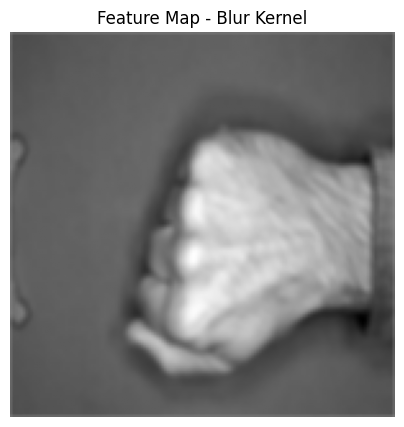

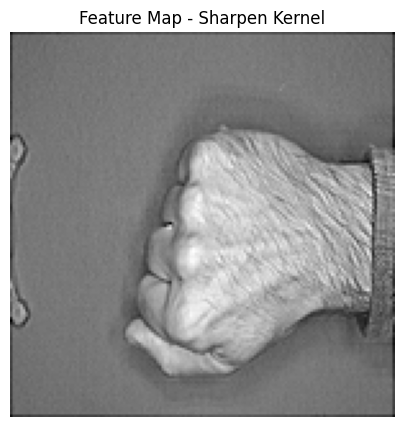

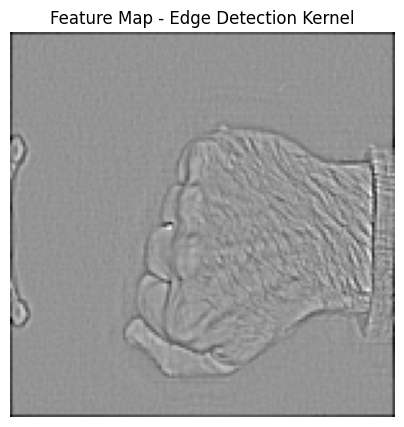

In [85]:
# Visualizing the outputs (feature maps) with different kernels
# For visualization, we'll create separate Conv2d layers and set their weights.
def visualize_feature_maps(image_batch, kernel, kernel_name, in_channels=3):
    # Applies a specific kernel using Conv2d and visualizes the output feature map.
    if image_batch is None:
        print(f"Skipping visualization for {kernel_name}: No input image.")
        return

    out_channels = 1 # Visualize one output channel per kernel
    kernel_tensor = torch.tensor(kernel, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

    # Creating a kernel that applies to all input channels and sums the result
    # Weight shape: [out_channels, in_channels, kernel_height, kernel_width]
    kernel_tensor = kernel_tensor.repeat(out_channels, in_channels, 1, 1)

    # Creating a Conv2d layer for this specific kernel
    conv_layer = nn.Conv2d(in_channels, out_channels, kernel_size=kernel.shape[0], padding='same', bias=False) # Use 'same' padding

    # Manually set the weights of the layer
    conv_layer.weight.data = kernel_tensor

    # Applying the layer
    conv_layer.eval()
    with torch.no_grad():
        feature_map = conv_layer(image_batch)

    # Visualization
    plt.figure(figsize=(5, 5))
    plt.imshow(feature_map[0, 0].numpy(), cmap='gray') # Visualize the first (and only) output channel
    plt.title(f'Feature Map - {kernel_name} Kernel')
    plt.axis('off')
    plt.show()

# Defining kernels (examples)
blur_kernel = np.array([[1, 1, 1], [1, 1, 1], [1, 1, 1]], dtype=np.float32) / 9.0
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
edge_detect_kernel = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=np.float32) # using laplacian edge detection

# Visualizing feature maps for each kernel
visualize_feature_maps(single_image_batch, blur_kernel, "Blur", in_channels=input_channels)
visualize_feature_maps(single_image_batch, sharpen_kernel, "Sharpen", in_channels=input_channels)
visualize_feature_maps(single_image_batch, edge_detect_kernel, "Edge Detection", in_channels=input_channels)


Experimenting with Kernel Size, Stride, Padding

Experiment: Larger Kernel (5x5)
  Input Size: (150, 150)
  Params: Kernel=5, Stride=1, Padding=2
  Expected Output Size (H, W): (150, 150)
  Actual Output Shape: torch.Size([1, 4, 150, 150])
  Actual Output Size (H, W): (150, 150)
  Dimensions match expected.


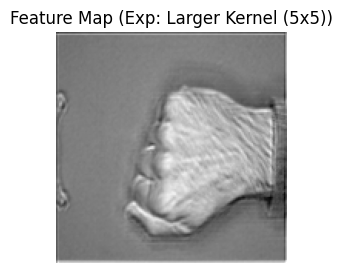


Experiment: Stride=2
  Input Size: (150, 150)
  Params: Kernel=3, Stride=2, Padding=1
  Expected Output Size (H, W): (75, 75)
  Actual Output Shape: torch.Size([1, 4, 75, 75])
  Actual Output Size (H, W): (75, 75)
  Dimensions match expected.


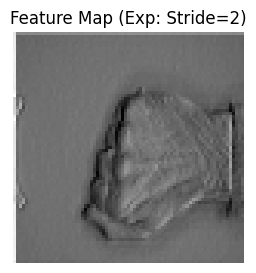


Experiment: No Padding
  Input Size: (150, 150)
  Params: Kernel=3, Stride=1, Padding=0
  Expected Output Size (H, W): (148, 148)
  Actual Output Shape: torch.Size([1, 4, 148, 148])
  Actual Output Size (H, W): (148, 148)
  Dimensions match expected.


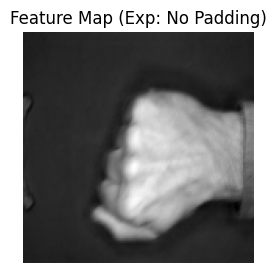


Experiment: Kernel=7, Stride=3, Pad=1
  Input Size: (150, 150)
  Params: Kernel=7, Stride=3, Padding=1
  Expected Output Size (H, W): (49, 49)
  Actual Output Shape: torch.Size([1, 4, 49, 49])
  Actual Output Size (H, W): (49, 49)
  Dimensions match expected.


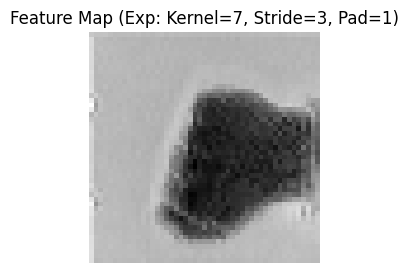

In [86]:
# Experimenting by changing kernel size, stride, and padding [cite: 32]
print("\nExperimenting with Kernel Size, Stride, Padding")

experiments = [
    {'name': 'Larger Kernel (5x5)', 'kernel_size': 5, 'stride': 1, 'padding': 2}, # Padding = 'same' roughly
    {'name': 'Stride=2', 'kernel_size': 3, 'stride': 2, 'padding': 1},
    {'name': 'No Padding', 'kernel_size': 3, 'stride': 1, 'padding': 0},
    {'name': 'Kernel=7, Stride=3, Pad=1', 'kernel_size': 7, 'stride': 3, 'padding': 1},
]

if single_image_batch is not None:
    C_in = input_channels
    H_in, W_in = single_image_batch.shape[2], single_image_batch.shape[3]
    out_channels_exp = 4 # here use fewer channels for easier display if needed

    for exp in experiments:
        print(f"\nExperiment: {exp['name']}")
        kernel_size = exp['kernel_size']
        stride = exp['stride']
        padding = exp['padding']

        # Calculating expected size
        H_exp, W_exp = calculate_conv_output_size(H_in, W_in, kernel_size, padding, stride)
        print(f"  Input Size: ({H_in}, {W_in})")
        print(f"  Params: Kernel={kernel_size}, Stride={stride}, Padding={padding}")
        print(f"  Expected Output Size (H, W): ({H_exp}, {W_exp})")

        # Creating model
        model_exp = SimpleCNN(in_channels=C_in,
                              out_channels=out_channels_exp,
                              kernel_size=kernel_size,
                              stride=stride,
                              padding=padding)
        # Applying model
        model_exp.eval()
        with torch.no_grad():
            output_exp = model_exp(single_image_batch)

        # Printing actual size
        H_act, W_act = output_exp.shape[2], output_exp.shape[3]
        print(f"  Actual Output Shape: {output_exp.shape}")
        print(f"  Actual Output Size (H, W): ({H_act}, {W_act})")

        if (H_act, W_act) == (H_exp, W_exp):
            print("  Dimensions match expected.")
        else:
            print("  [Warning] Dimensions DO NOT match expected.")

        # Visualizing one feature map from the experiment
        if output_exp.shape[1] > 0:
             plt.figure(figsize=(3, 3))
             plt.imshow(output_exp[0, 0].numpy(), cmap='grey')
             plt.title(f"Feature Map (Exp: {exp['name']})")
             plt.axis('off')
             plt.show()

else:
    print("Skipping experiments as no input image was loaded.")


**3.3 Pooling Functions**

In [87]:
# extending CNN Class to include pooling layer (nn.MaxPool2d)
# let's create a new class for it not extending to the original class
class CNNWithPooling(nn.Module):
    def __init__(self, in_channels, out_channels_conv, kernel_size_conv, stride_conv, padding_conv,
                 kernel_size_pool, stride_pool):
        super(CNNWithPooling, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels_conv, kernel_size=kernel_size_conv,
                               stride=stride_conv, padding=padding_conv)
        self.relu1 = nn.ReLU()
        # Pooling Layer
        self.pool1 = nn.MaxPool2d(kernel_size=kernel_size_pool, stride=stride_pool)

    def forward(self, x):
        x_conv = self.conv1(x)
        x_activated = self.relu1(x_conv)
        x_pooled = self.pool1(x_activated)
        # here we are returning intermediate steps for visualization if needed
        return x_conv, x_activated, x_pooled


In [88]:
# creating function to calculate MaxPool output size
def calculate_pool_output_size(H_in, W_in, kernel_size, stride):
     if isinstance(kernel_size, int): kernel_size = (kernel_size, kernel_size)
     if isinstance(stride, int): stride = (stride, stride)
     H_out = np.floor(((H_in - kernel_size[0]) / stride[0]) + 1)
     W_out = np.floor(((W_in - kernel_size[1]) / stride[1]) + 1)
     return int(H_out), int(W_out)

Shape before Pooling (after Conv): torch.Size([1, 16, 150, 150])
Shape before Pooling (after ReLU): torch.Size([1, 16, 150, 150])
Shape after Max Pooling: torch.Size([1, 16, 75, 75])
Input Size to Pooling (H, W): (150, 150)
Pooling Params: Kernel=2, Stride=2
Expected Output Size after Pooling (H, W): (75, 75)
Actual Output Size after Pooling (H, W): (75, 75)
Pooling output dimensions match expected dimensions.


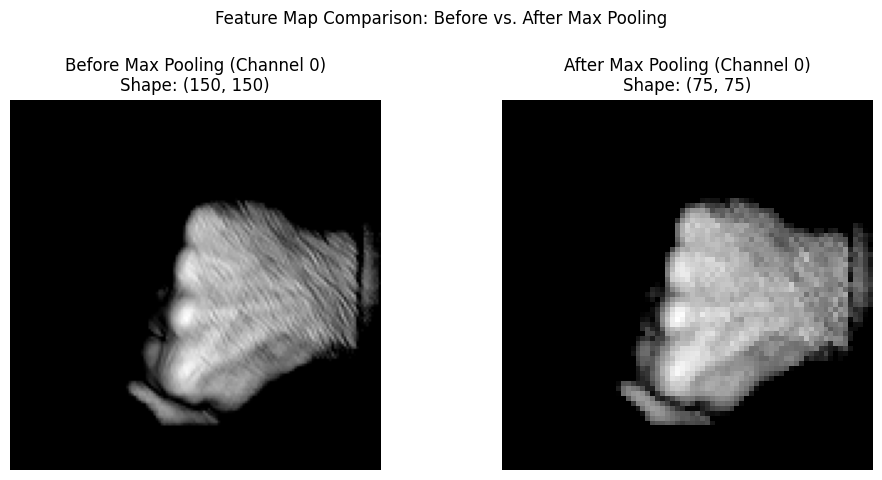

In [93]:
# max pooling
if output_features is not None:
    # Parameters for Max Pooling
    kernel_size_pool = 2
    stride_pool = 2
    if 'model_conv' in globals() and model_conv is not None:
        in_channels_recap = model_conv.conv1.in_channels
        out_channels_recap = model_conv.conv1.out_channels
        kernel_size_recap = model_conv.conv1.kernel_size[0] # Assuming square kernel
        stride_recap = model_conv.conv1.stride[0]          # Assuming square stride
        padding_recap = model_conv.conv1.padding[0]        # Assuming square padding

        # Instantiating the new model
        model_pool = CNNWithPooling(in_channels=in_channels_recap, out_channels_conv=out_channels_recap,
                                    kernel_size_conv=kernel_size_recap, stride_conv=stride_recap, padding_conv=padding_recap,
                                    kernel_size_pool=kernel_size_pool, stride_pool=stride_pool)

        # Applying the model
        model_pool.eval()
        with torch.no_grad():
             features_before_pool_raw, features_before_pool_act, features_after_pool = model_pool(single_image_batch)

        print(f"Shape before Pooling (after Conv): {features_before_pool_raw.shape}")
        print(f"Shape before Pooling (after ReLU): {features_before_pool_act.shape}")
        print(f"Shape after Max Pooling: {features_after_pool.shape}")

        # Verifying output size after pooling
        H_before_pool, W_before_pool = features_before_pool_act.shape[2], features_before_pool_act.shape[3]
        H_pool_expected, W_pool_expected = calculate_pool_output_size(H_before_pool, W_before_pool,
                                                                    kernel_size_pool, stride_pool)
        H_pool_actual, W_pool_actual = features_after_pool.shape[2], features_after_pool.shape[3]

        print(f"Input Size to Pooling (H, W): ({H_before_pool}, {W_before_pool})")
        print(f"Pooling Params: Kernel={kernel_size_pool}, Stride={stride_pool}")
        print(f"Expected Output Size after Pooling (H, W): ({H_pool_expected}, {W_pool_expected})")
        print(f"Actual Output Size after Pooling (H, W): ({H_pool_actual}, {W_pool_actual})")

        if (H_pool_actual, W_pool_actual) == (H_pool_expected, W_pool_expected):
            print("Pooling output dimensions match expected dimensions.")
        else:
            print("[Warning] Pooling output dimensions DO NOT match expected dimensions!")

        # Visualizing and comparing feature maps before and after pooling
        channel_to_visualize = 0
        if features_before_pool_act.shape[1] > channel_to_visualize and features_after_pool.shape[1] > channel_to_visualize:
            map_before = features_before_pool_act[0, channel_to_visualize].numpy()
            map_after = features_after_pool[0, channel_to_visualize].numpy()

            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(map_before, cmap='gray')
            axes[0].set_title(f'Before Max Pooling (Channel {channel_to_visualize})\nShape: {map_before.shape}')
            axes[0].axis('off')

            axes[1].imshow(map_after, cmap='gray')
            axes[1].set_title(f'After Max Pooling (Channel {channel_to_visualize})\nShape: {map_after.shape}')
            axes[1].axis('off')

            plt.suptitle('Feature Map Comparison: Before vs. After Max Pooling')
            plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # here adjust layout to prevent title overlap
            plt.show()
        else:
            print(f"Cannot visualize channel {channel_to_visualize}, check output shapes.")

    else:
        print("Skipping Max Pooling visualization/verification: `model_conv` not found.")

else:
    print("Skipping Max Pooling visualization/verification: `output_features` not available.")

In [94]:
# Global Average Pooling
if output_features is not None: # Using output_features (output of first conv layer) as input to GAP
    #    GAP reduces each feature map channel to a single value (1x1 output size).
    gap_layer = nn.AdaptiveAvgPool2d((1, 1))

    # Applying GAP to the feature maps obtained *after convolution* (output_features)
    # Let's apply it to the output of the initial convolution for this specific step.
    input_to_gap = output_features # Or we can use features_before_pool_act or features_after_pool

    print(f"Shape before GAP: {input_to_gap.shape}") # this should be [Batch, Channels, H, W]

    output_gap = gap_layer(input_to_gap)

    print(f"Shape after GAP: {output_gap.shape}") # Expected: [Batch, Channels, 1, 1]

    # Verifying output size
    expected_gap_shape = (input_to_gap.shape[0], input_to_gap.shape[1], 1, 1)
    actual_gap_shape = output_gap.shape

    if actual_gap_shape == expected_gap_shape:
        print("GAP output dimensions match expected dimensions ([Batch, Channels, 1, 1]).")
    else:
        print("[Warning] GAP output dimensions DO NOT match expected dimensions!")
        print(f"Expected {expected_gap_shape}, Got {actual_gap_shape}")

else:
    print("Skipping GAP verification: `output_features` not available.")

Shape before GAP: torch.Size([1, 16, 150, 150])
Shape after GAP: torch.Size([1, 16, 1, 1])
GAP output dimensions match expected dimensions ([Batch, Channels, 1, 1]).


**3.4 Building the Complete CNN Model**

In [123]:
# creating a new class which is extension of above CNNWithPooling class to build the complete CNN model
class CompleteCNN(nn.Module):
    def __init__(self, input_channels, num_classes):
        super(CompleteCNN, self).__init__()

        # Convolutional Block 1
        self.conv1 = nn.Conv2d(input_channels, 32, kernel_size=3, stride=1, padding=1) # Example: 32 filters
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # Example: 2x2 pooling

        # Convolutional Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1) # Example: 64 filters
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Convolutional Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1) # Example: 128 filters
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Global Average Pooling
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

        # here the input size to the first linear layer depends on the number of output channels
        # from the last convolutional block (128 in this example).
        self.fc1_hidden = nn.Linear(128, 256) # Example: 256 hidden units
        self.relu_fc1 = nn.ReLU()
        self.fc2_output = nn.Linear(256, num_classes)

    def forward(self, x, print_shapes=False):
        if print_shapes: print(f"Input shape: {x.shape}")

        # Block 1
        x = self.conv1(x)
        if print_shapes: print(f"After Conv1: {x.shape}")
        x = self.relu1(x)
        if print_shapes: print(f"After ReLU1: {x.shape}") # here shape doesn't change
        x = self.pool1(x)
        if print_shapes: print(f"After Pool1: {x.shape}")

        # Block 2
        x = self.conv2(x)
        if print_shapes: print(f"After Conv2: {x.shape}")
        x = self.relu2(x)
        if print_shapes: print(f"After ReLU2: {x.shape}")
        x = self.pool2(x)
        if print_shapes: print(f"After Pool2: {x.shape}")

        # Block 3
        x = self.conv3(x)
        if print_shapes: print(f"After Conv3: {x.shape}")
        x = self.relu3(x)
        if print_shapes: print(f"After ReLU3: {x.shape}")
        x = self.pool3(x)
        if print_shapes: print(f"After Pool3: {x.shape}")

        # Global Average Pooling
        x = self.gap(x)
        if print_shapes: print(f"After GAP: {x.shape}") # here it should be [N, 128, 1, 1]

        x = x.view(x.size(0), -1)
        if print_shapes: print(f"After Flatten: {x.shape}") # here it should be [N, 128]

        # MLP
        x = self.fc1_hidden(x)
        if print_shapes: print(f"After FC1 (Hidden): {x.shape}")
        x = self.relu_fc1(x)
        if print_shapes: print(f"After ReLU FC1: {x.shape}")
        x = self.fc2_output(x)
        if print_shapes: print(f"After FC2 (Output): {x.shape}") # here it should be [N, num_classes]

        return x

In [124]:
'''
 Printing and verifying the dimensions after each convolution, activation, pooling, GAP, and fully connected layer to ensure
 they match your expectations.
'''
can_verify_dimensions = single_image_batch is not None # Or any other conditions you need to check

if can_verify_dimensions:
    # Getting input channels from the sample batch
    input_channels = single_image_batch.shape[1]

    # Instantiating the model
    complete_model = CompleteCNN(input_channels=input_channels, num_classes=num_classes)
    print("\nComplete CNN Model Architecture:")
    print(complete_model)

    # Printing and verifying dimensions
    print("\nVerifying dimensions with a sample batch:")
    complete_model.eval() # Setting to evaluation mode for dimension checking
    with torch.no_grad():
        # Passing the sample batch through the forward method with print_shapes=True
        output_logits = complete_model(single_image_batch, print_shapes=True)

    print(f"\nFinal output shape (logits): {output_logits.shape}")
    # Checking if final shape matches [batch_size, num_classes]
    expected_final_shape = (single_image_batch.shape[0], num_classes)
    if output_logits.shape == expected_final_shape:
        print("Final output dimensions match expected dimensions.")
    else:
        print("[Warning] Final output dimensions DO NOT match expected dimensions!")
        print(f"Expected: {expected_final_shape}, Got: {output_logits.shape}")

else:
    print("\nCannot verify dimensions as 'single_image_batch' is not available.")


Complete CNN Model Architecture:
CompleteCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc1_hidden): Linear(in_features=128, out_features=256, bias=True)
  (relu_fc1): ReLU()
  (fc2_output): Linear(in_features=256, out_features=3, bias=True)
)

Verifying dimensions with a sample batch:
Input shape: torch.Size([1, 3, 150, 150])
After Conv1: torch.Size([1, 32, 150, 150])
After ReLU1: torch.Size([1, 32, 150, 150])
After Pool1: torch.Size([1, 32, 7

**3.5 Training and Evaluation**

model and dataoaders are ready for training.
Using device: cuda
Starting training for 30 epochs...
Epoch [1/30] | Train Loss: 1.0972 | Train Acc: 34.63% | Test Loss: 1.0983 | Test Acc: 32.88%
Epoch [2/30] | Train Loss: 1.0930 | Train Acc: 35.20% | Test Loss: 1.0931 | Test Acc: 33.11%
Epoch [3/30] | Train Loss: 1.0880 | Train Acc: 38.06% | Test Loss: 1.0872 | Test Acc: 36.30%
Epoch [4/30] | Train Loss: 1.0777 | Train Acc: 39.89% | Test Loss: 1.0689 | Test Acc: 39.50%
Epoch [5/30] | Train Loss: 1.0542 | Train Acc: 42.74% | Test Loss: 1.0562 | Test Acc: 40.64%
Epoch [6/30] | Train Loss: 1.0369 | Train Acc: 46.69% | Test Loss: 0.9915 | Test Acc: 61.64%
Epoch [7/30] | Train Loss: 1.0404 | Train Acc: 45.89% | Test Loss: 1.1010 | Test Acc: 36.07%
Epoch [8/30] | Train Loss: 1.0295 | Train Acc: 44.40% | Test Loss: 0.9584 | Test Acc: 69.41%
Epoch [9/30] | Train Loss: 1.0020 | Train Acc: 46.69% | Test Loss: 1.1230 | Test Acc: 35.62%
Epoch [10/30] | Train Loss: 1.0343 | Train Acc: 45.09% | Test Lo

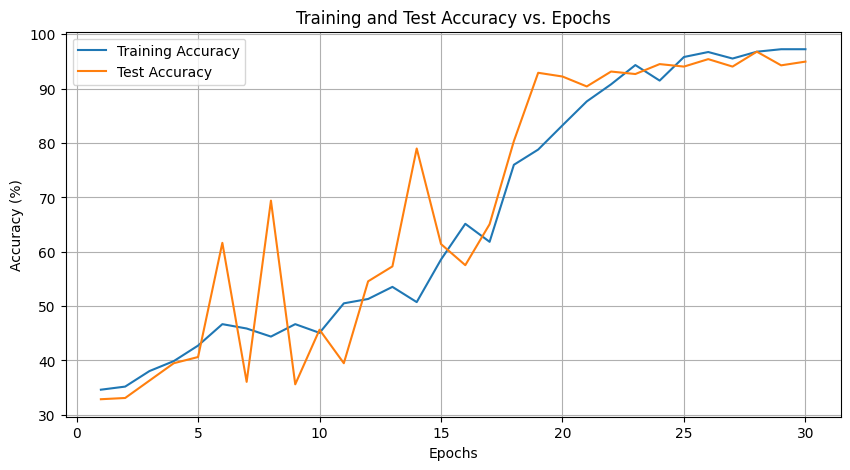

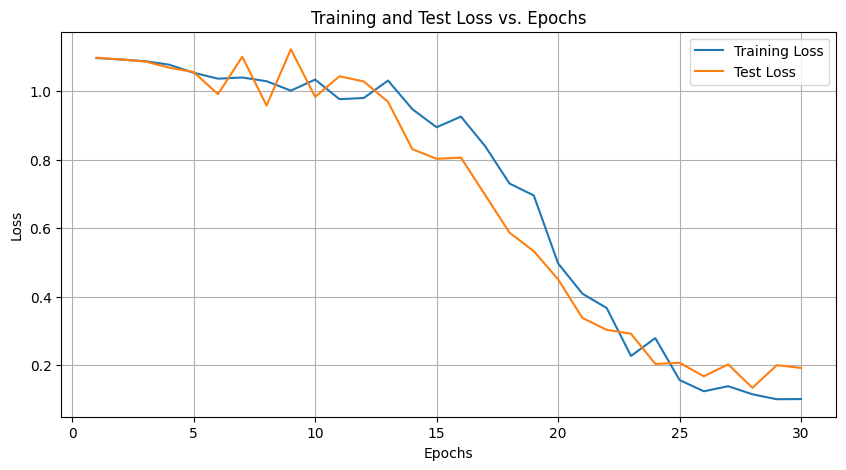

In [125]:
# checking if necessary components are available
model_ready = 'complete_model' in globals() and complete_model is not None
data_ready = 'train_loader' in globals() and train_loader is not None and 'test_loader' in globals() and test_loader is not None

if model_ready and data_ready:
    print("model and dataoaders are ready for training.")
    # here we can change hyperpameters for better results
    learning_rate = 0.1
    num_epochs = 30
    # batch_size is determined by DataLoader definition earlier

    # creating Loss Function and Optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(complete_model.parameters(), lr=learning_rate)

    # creating Device configuration (we can use GPU if available, otherwise CPU)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    complete_model.to(device)

    # creating Lists to store metrics
    train_loss_history = []
    test_loss_history = []
    train_acc_history = []
    test_acc_history = []

    print(f"Starting training for {num_epochs} epochs...")

    start_time = time.time()

    for epoch in range(num_epochs):
        # Training Phase
        complete_model.train() # Setting the model to training mode
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for i, (inputs, labels) in enumerate(train_loader):
            inputs, labels = inputs.to(device), labels.to(device)

            # making parameter gradients zero
            optimizer.zero_grad()

            # Forward pass
            outputs = complete_model(inputs)
            loss = criterion(outputs, labels)

            # Backward pass and optimize
            loss.backward()
            optimizer.step()

            # Tracking statistics
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()


        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = 100 * correct_train / total_train
        train_loss_history.append(epoch_train_loss)
        train_acc_history.append(epoch_train_acc)

        # Evaluation Phase
        complete_model.eval() # Setting the model to evaluation mode
        running_test_loss = 0.0
        correct_test = 0
        total_test = 0

        with torch.no_grad(): # here we dont need to track gradients during evaluation
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                # Forward pass
                outputs = complete_model(inputs)
                loss = criterion(outputs, labels)

                # Track statistics
                running_test_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()

        epoch_test_loss = running_test_loss / len(test_loader.dataset)
        epoch_test_acc = 100 * correct_test / total_test
        test_loss_history.append(epoch_test_loss)
        test_acc_history.append(epoch_test_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}] | "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
              f"Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.2f}%")

    end_time = time.time()
    print(f"Training finished in {end_time - start_time:.2f} seconds.")

    # Plotting Training and Test Accuracy Curves
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, num_epochs + 1), train_acc_history, label='Training Accuracy')
    plt.plot(range(1, num_epochs + 1), test_acc_history, label='Test Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Test Accuracy vs. Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Plotting Training and Test Loss Curves
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, num_epochs + 1), train_loss_history, label='Training Loss')
    plt.plot(range(1, num_epochs + 1), test_loss_history, label='Test Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training and Test Loss vs. Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("\nSkipping Training and Evaluation: Model or DataLoaders not available.")
    if not model_ready:
        print("Reason: 'complete_model' is not defined or is None. Ensure Section 3.4 ran successfully.")
    if not data_ready:
        print("Reason: 'train_loader' or 'test_loader' is not defined or is None. Ensure Section 3.1 ran successfully.")


**Results based on Hyperparameter Experimentation**

**Model Performance Based on Hyperparameters**

1.  **Learning Rate**: *When this is between 0.1 and 0.01, the model performs well(that to when lr is 0.1).*
   
2.  **Epochs**: *When epochs are 15, the model performs badly, and when epochs are 30, the model performs very well.*
   
3.  **Batch Sizes**: *Based on experimentation, when batch sizes are small (e.g., 16), the model's training is slower but it may generalize slightly better. When batch sizes are larger (e.g., 64), the training is faster, but we may observe a slight decrease in generalization performance.*